# 4. Polynomial interpolation and Chebyshev points

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/04_polynomial_interpolation.ipynb)

*Companion to Chapter 5 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

The Fourier methods of notebooks 1 to 3 need periodic functions. Most engineering problems are
not periodic: a rod has two ends, a channel has two walls. On a bounded interval the natural
global interpolant is no longer a sum of sines and cosines but a single **polynomial** through
all the data. Whether that works depends entirely on where the data points are. In equally
spaced points it fails, sometimes spectacularly. In **Chebyshev points**, which crowd towards
the ends of the interval, it converges as fast as the Fourier methods did.

You will see:

- the barycentric formula, a fast and stable way to evaluate an interpolating polynomial
- the Runge phenomenon in equally spaced points, and its absence in Chebyshev points
- the explanation, from the size of the node polynomial and its potential
- Lebesgue constants: how much an interpolation process amplifies errors in the data
- the convergence rate, read off from an ellipse in the complex plane

**Worked example:** tabulating the latent heat of vaporization of water with 12 points.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 4.1 The interpolating polynomial and how to evaluate it

Given values $u_0, \dots, u_N$ at distinct points $x_0, \dots, x_N$, there is exactly one
polynomial $P$ of degree at most $N$ with $P(x_j) = u_j$. The question of this section is how
to compute $P(x)$ at some other point $x$.

**By hand.** The Lagrange form writes $P(x) = \sum_j u_j\,\ell_j(x)$, where $\ell_j$ is the
polynomial of degree $N$ that equals 1 at $x_j$ and 0 at the other points:

$$\ell_j(x) = \prod_{k \ne j}\frac{x - x_k}{x_j - x_k} .$$

Two pieces of notation tidy this up. The **node polynomial** is $p(x) = \prod_{k=0}^{N}(x - x_k)$,
the polynomial that vanishes at every point. The **barycentric weights** are

$$\lambda_j = \frac{1}{\prod_{k \ne j}(x_j - x_k)} .$$

The numerator of $\ell_j$ is $p(x)$ with the factor $(x - x_j)$ removed, so
$\ell_j(x) = p(x)\,\dfrac{\lambda_j}{x - x_j}$ and

$$P(x) = p(x)\sum_{j=0}^{N}\frac{\lambda_j}{x - x_j}\,u_j .$$

This holds for any data, in particular for $u_j = 1$, whose interpolant is the constant 1:
$1 = p(x)\sum_j \lambda_j/(x - x_j)$. Dividing the two equations removes $p(x)$:

$$P(x) = \frac{\displaystyle\sum_{j=0}^{N}\frac{\lambda_j}{x - x_j}\,u_j}{\displaystyle\sum_{j=0}^{N}\frac{\lambda_j}{x - x_j}} .$$

This is the **barycentric formula**. Once the weights are known it costs $O(N)$ operations per
evaluation point, it never forms the coefficients of the polynomial, and a factor common to all
the weights cancels. If $x$ coincides with a point $x_j$ the formula reads $\infty/\infty$ and
the answer is $u_j$.

In [2]:
def barycentric_weights(nodes):
    """Barycentric weights λ_j = 1 / prod_{k≠j} (x_j - x_k) for any set of distinct points."""
    nodes = np.asarray(nodes, dtype=float)
    dx = nodes[:, None] - nodes[None, :]
    np.fill_diagonal(dx, 1.0)
    return 1 / dx.prod(axis=1)

def lagrange_interpolate(nodes, values, x_eval):
    """Evaluate the polynomial interpolant through (nodes, values) at x_eval, by the barycentric formula."""
    nodes, values = np.asarray(nodes, dtype=float), np.asarray(values, dtype=float)
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - nodes[None, :]
    exact = diff == 0                                           # evaluation points that hit a node
    diff[exact] = 1.0
    ratio = barycentric_weights(nodes) / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

**Verify.** The interpolant of a polynomial of degree at most $N$ is that polynomial. Take a
quintic and six arbitrary points.

In [3]:
rng = np.random.default_rng(0)
nodes = np.sort(rng.uniform(-1, 1, 6))
quintic = lambda x: 3 * x**5 - x**4 + 2 * x**2 - 7 * x + 1
x_test = np.linspace(-1, 1, 201)
assert np.abs(lagrange_interpolate(nodes, quintic(nodes), x_test) - quintic(x_test)).max() < 1e-12
assert np.allclose(lagrange_interpolate(nodes, quintic(nodes), nodes), quintic(nodes))     # at the nodes themselves
assert np.allclose(barycentric_weights([-1.0, 0.0, 1.0]), [1 / 2, -1, 1 / 2])

## 4.2 Equally spaced points fail

**Problem.** The function

$$f(x) = \frac{1}{1 + 25x^2},\qquad -1 \le x \le 1,$$

has the shape of a resonance peak or a spectral line, centred at 0 with half-width $1/5$. It is
smooth: every derivative exists everywhere. Sample it at $N + 1$ points and pass the polynomial
of degree $N$ through the samples. Does the polynomial approach $f$ as $N$ grows?

Try two sets of points: equally spaced, $x_j = -1 + 2j/N$, and the **Chebyshev points**
$x_j = \cos(j\pi/N)$, which section 4.3 examines.

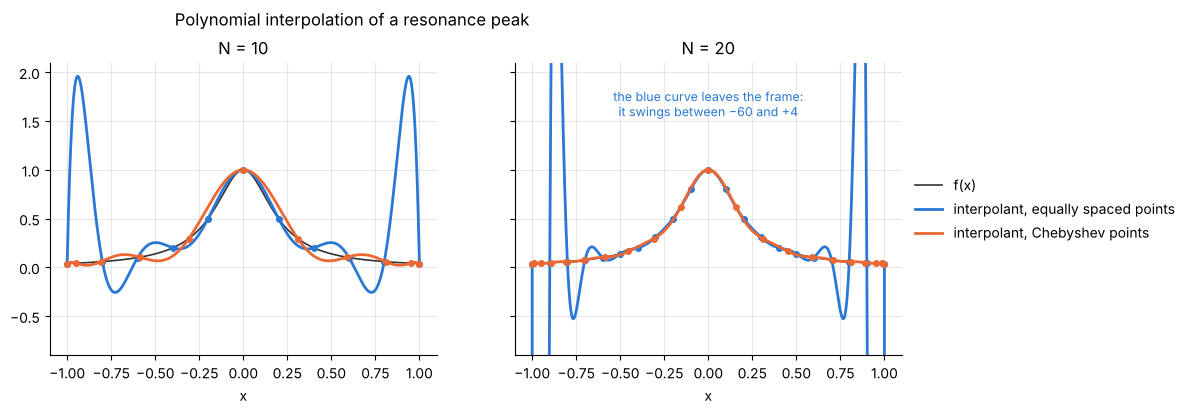

In [4]:
def runge(x):
    return 1 / (1 + 25 * x**2)

def equispaced_points(N):
    return np.linspace(-1, 1, N + 1)

def chebyshev_points(N):
    return np.cos(np.pi * np.arange(N + 1) / N)                # x_0 = 1 down to x_N = -1

x_fine = np.linspace(-1, 1, 2001)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, N in zip(axes, (10, 20)):
    ax.plot(x_fine, runge(x_fine), color="0.2", lw=1.2, label="f(x)")
    for points, name in ((equispaced_points(N), "equally spaced"), (chebyshev_points(N), "Chebyshev")):
        line, = ax.plot(x_fine, lagrange_interpolate(points, runge(points), x_fine), label=f"interpolant, {name} points")
        ax.plot(points, runge(points), "o", ms=4, color=line.get_color())
    ax.set(xlabel="x", ylim=(-0.9, 2.1), title=f"N = {N}")
axes[1].annotate("the blue curve leaves the frame:\nit swings between −60 and +4", xy=(0, 1.55), ha="center", fontsize=9, color="C0")
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.suptitle("Polynomial interpolation of a resonance peak", x=0.4, y=1.02);

In [5]:
N_table = np.arange(10, 61, 10)
equispaced_errors = [np.abs(lagrange_interpolate(equispaced_points(N), runge(equispaced_points(N)), x_fine) - runge(x_fine)).max() for N in N_table]
chebyshev_errors = [np.abs(lagrange_interpolate(chebyshev_points(N), runge(chebyshev_points(N)), x_fine) - runge(x_fine)).max() for N in N_table]
print("  N    equally spaced    Chebyshev")
for N, e_equi, e_cheb in zip(N_table, equispaced_errors, chebyshev_errors):
    print(f"{N:3d} {e_equi:14.1e} {e_cheb:14.1e}")
assert np.all(np.diff(equispaced_errors) > 0) and equispaced_errors[-1] > 1e7
assert np.all(np.diff(chebyshev_errors) < 0) and chebyshev_errors[-1] < 1e-5

  N    equally spaced    Chebyshev
 10        1.9e+00        1.3e-01
 20        6.0e+01        1.8e-02
 30        2.4e+03        2.4e-03
 40        1.0e+05        3.4e-04
 50        4.8e+06        4.6e-05
 60        1.5e+08        6.4e-06


In equally spaced points the interpolant matches the function in the middle and oscillates
wildly near the ends, and **more points make it worse**: the largest error grows from 2 at
$N = 10$ to $10^8$ at $N = 60$. This is the **Runge phenomenon**. It is not caused by rounding
errors or by a bad algorithm. It is what the exact interpolating polynomial does.

In Chebyshev points the same procedure converges steadily, gaining a digit for every 12 points
or so. The rest of this notebook explains the difference.

## 4.3 Chebyshev points

**By hand.** Place $N + 1$ points at equal angles $\theta_j = j\pi/N$ on the upper half of the
unit circle and drop each one onto the horizontal axis:

$$x_j = \cos\frac{j\pi}{N},\qquad j = 0, 1, \dots, N .$$

The points run from $x_0 = 1$ down to $x_N = -1$, right to left. Equal steps in $\theta$ give
unequal steps in $x$. Since $dx = -\sin\theta\,d\theta$ and $\sin\theta = \sqrt{1 - x^2}$, the
number of points per unit length near $x$ is

$$\text{density} = \frac{N}{\pi\sqrt{1 - x^2}} .$$

In the middle the density is $N/\pi$, so the spacing is about $\pi/N$, which is $\pi/2$ times
coarser than $N + 1$ equally spaced points. Towards the ends the density grows without bound.
The first gap is $1 - \cos(\pi/N) \approx \dfrac{\pi^2}{2N^2}$: it shrinks like $1/N^2$, not $1/N$.

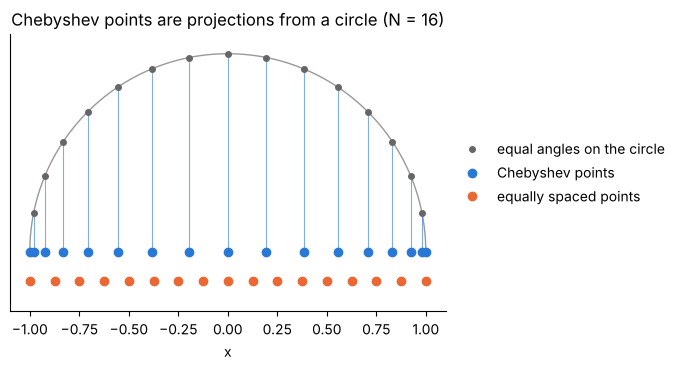

In [6]:
N = 16
angles = np.pi * np.arange(N + 1) / N
arc = np.linspace(0, np.pi, 200)
fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.plot(np.cos(arc), np.sin(arc), color="0.6", lw=1)
ax.vlines(np.cos(angles), 0, np.sin(angles), color="C0", lw=0.8, alpha=0.6)
ax.plot(np.cos(angles), np.sin(angles), "o", ms=4, color="0.4", label="equal angles on the circle")
ax.plot(np.cos(angles), np.zeros(N + 1), "o", ms=6, color="C0", label="Chebyshev points")
ax.plot(equispaced_points(N), np.full(N + 1, -0.15), "o", ms=6, color="C1", label="equally spaced points")
ax.set(xlabel="x", yticks=[], ylim=(-0.3, 1.1), title=f"Chebyshev points are projections from a circle (N = {N})")
ax.set_aspect("equal")
ax.grid(False)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

**Verify** the two spacing estimates.

In [7]:
N = 50
x = chebyshev_points(N)
end_gap, middle_gap = x[0] - x[1], x[N // 2 - 1] - x[N // 2]
print(f"N = {N}: end gap {end_gap:.5f} (π²/2N² = {np.pi**2 / (2 * N**2):.5f}),  middle gap {middle_gap:.5f} (π/N = {np.pi / N:.5f})")
assert abs(end_gap / (np.pi**2 / (2 * N**2)) - 1) < 0.01 and abs(middle_gap / (np.pi / N) - 1) < 0.01

N = 50: end gap 0.00197 (π²/2N² = 0.00197),  middle gap 0.06279 (π/N = 0.06283)


With 51 points the gap at the ends is thirty times smaller than in the middle. That looks like
a waste of points. Section 4.4 shows it is exactly what a polynomial needs.

## 4.4 Why: the node polynomial and its potential

**By hand.** The classical error formula for polynomial interpolation is

$$f(x) - P(x) = \frac{f^{(N+1)}(\xi)}{(N+1)!}\,p(x),\qquad p(x) = \prod_{j=0}^{N}(x - x_j),$$

for some $\xi$ in the interval. The function enters through a derivative, and the **points**
enter only through the node polynomial $p$. Wherever $|p(x)|$ is large the error is large. So
compare the size of $p$ along the interval for the two point sets. Products of many factors are
best handled through their logarithm:

$$|p(z)| = e^{N\phi_N(z)},\qquad \phi_N(z) = \frac1N\sum_{j=0}^{N}\log|z - x_j| .$$

The function $\phi_N$ has a physical reading: $\log|z - x_j|$ is the two-dimensional potential
at $z$ of a line charge at $x_j$, so $\phi_N$ is the **potential** of equal charges placed at
the interpolation points. It is defined for complex $z$ as well, which will matter shortly. As
$N \to \infty$ the charges smear into a continuous density and $\phi_N$ tends to a limit $\phi$.

- **Equally spaced points** have uniform density, and the integral
  $\phi(x) = \tfrac12\int_{-1}^{1}\log|x - t|\,dt$ can be done by hand:
  $\phi(x) = -1 + \tfrac12\big[(1+x)\log(1+x) + (1-x)\log(1-x)\big]$. This varies along the
  interval, from $\phi(0) = -1$ at the centre to $\phi(\pm1) = -1 + \log 2$ at the ends. So $|p|$
  is larger near the ends than at the centre by a factor of about $e^{N\log 2} = 2^N$.
- **Chebyshev points** have the density of 4.3, and for that density the potential is
  **constant** on the interval: $\phi(x) = -\log 2$ for all $-1 \le x \le 1$. The node polynomial
  has the same size everywhere. The crowding at the ends is exactly what is needed to hold
  $p$ down there.

**Verify** the limiting values numerically with $N = 2000$. The potential is $-\infty$ at the
points themselves, so it is sampled midway between neighbouring points.

In [8]:
def potential(z, nodes):
    """φ_N(z) = (1/N) Σ log|z - x_j| for the N + 1 points in nodes; z may be complex."""
    return np.log(np.abs(np.asarray(z)[..., None] - nodes)).sum(axis=-1) / (len(nodes) - 1)

N = 2000
x_equi, x_cheb = equispaced_points(N), chebyshev_points(N)
phi_equi = potential((x_equi[:-1] + x_equi[1:]) / 2, x_equi)                    # midpoints, from the left end to the right end
phi_cheb = potential(np.cos(np.pi * (np.arange(N) + 0.5) / N), x_cheb)

print(f"equally spaced: centre {phi_equi[N // 2]:.4f} (limit -1),  ends {phi_equi[0]:.4f} (limit {-1 + np.log(2):.4f})")
print(f"Chebyshev:      between {phi_cheb.min():.4f} and {phi_cheb.max():.4f} on the whole interval (limit {-np.log(2):.4f})")
assert abs(phi_equi[N // 2] + 1) < 0.01 and abs(phi_equi[0] - (-1 + np.log(2))) < 0.01 and abs(phi_equi[-1] - phi_equi[0]) < 1e-9
assert np.abs(phi_cheb + np.log(2)).max() < 0.01

print("\nequally spaced points:")
print("  N    largest |p| near the end / largest |p| at the centre        2^N")
for N in (10, 20, 40):
    x_dense = np.linspace(-1, 1, 40001)
    size = np.abs(x_dense[:, None] - equispaced_points(N)).prod(axis=1)        # |p(x)|
    print(f"{N:3d} {size[x_dense > 1 - 2 / N].max() / size[np.abs(x_dense) < 1 / N].max():28.1e} {2.0**N:30.1e}")

equally spaced: centre -0.9997 (limit -1),  ends -0.3105 (limit -0.3069)
Chebyshev:      between -0.6964 and -0.6928 on the whole interval (limit -0.6931)

equally spaced points:
  N    largest |p| near the end / largest |p| at the centre        2^N
 10                      8.7e+01                        1.0e+03
 20                      5.4e+04                        1.0e+06
 40                      3.5e+10                        1.1e+12


The ratio grows exponentially. At these moderate $N$ it runs behind $2^N$ by a factor of 10 to
30, which grows only slowly with $N$ and which the limit ignores. That is the Runge phenomenon in
one line: in equally spaced points the node polynomial is enormously larger near the ends than
in the middle.

**Into the complex plane.** The error formula above needs high derivatives of $f$, which are
awkward. For an analytic function there is a sharper statement, quoted here without proof (it
follows from Cauchy's integral formula): if the singularity of $f$ nearest to the interval, in
the sense of the potential, is at $z_s$, then

$$|f(x) - P(x)| \approx \text{const} \times e^{N[\phi(x) - \phi(z_s)]} .$$

The interpolant converges at $x$ if the singularity sits at a **higher potential** than $x$,
and diverges if it sits at a lower one. The curves of constant $\phi$ in the complex plane,
the **equipotentials**, therefore decide everything. The function of 4.2 has its singularities
at the poles $z_s = \pm i/5$, where $1 + 25z^2 = 0$.

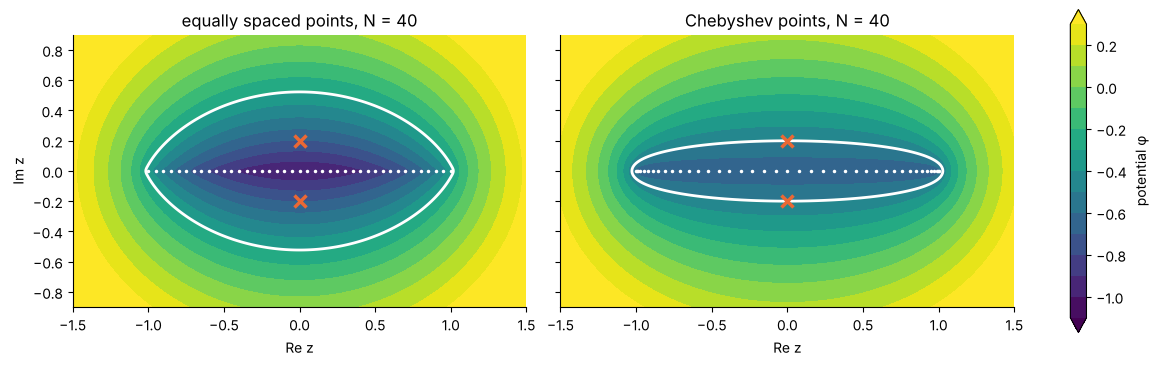

In [9]:
N = 40
re, im = np.meshgrid(np.linspace(-1.5, 1.5, 301), np.linspace(-0.9, 0.9, 180))        # 180 rows: none on the real axis
z = re + 1j * im
runge_rho = (1 + np.sqrt(26)) / 5                              # explained in 4.7
highlight = {"equally spaced": -1 + np.log(2), "Chebyshev": np.log(runge_rho / 2)}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9), sharey=True, constrained_layout=True)
for ax, (name, points) in zip(axes, (("equally spaced", equispaced_points(N)), ("Chebyshev", chebyshev_points(N)))):
    filled = ax.contourf(re, im, potential(z, points), levels=np.linspace(-1.1, 0.3, 15), cmap="viridis", extend="both")
    ax.contour(re, im, potential(z, points), levels=[highlight[name]], colors="white", linewidths=2, linestyles="solid")
    ax.plot(points, np.zeros(N + 1), ".", color="white", ms=3)
    ax.plot([0, 0], [0.2, -0.2], "x", color="C1", ms=9, mew=2.5)
    ax.set(xlabel="Re z", title=f"{name} points, N = {N}")
    ax.set_aspect("equal")
    ax.grid(False)
axes[0].set_ylabel("Im z")
fig.colorbar(filled, ax=axes, label="potential φ", shrink=0.85);

The white dots are the interpolation points and the orange crosses the poles of $f$.

- **Left.** The white curve is the equipotential through the end points $\pm1$. The interval
  is not an equipotential: its centre lies deep inside the curve, its ends on it. The poles at
  $\pm0.2i$ are inside too, at a lower potential than the ends, so near the ends the
  interpolant diverges. A function is safe in equally spaced points only if it is analytic in
  the whole lens-shaped region inside the white curve, which reaches $\pm0.5255i$ on the
  imaginary axis.
- **Right.** The interval itself is the lowest equipotential, and the others are ellipses
  around it. **Every** singularity off the interval is at a higher potential than every point
  on it, so interpolation in Chebyshev points converges for every function analytic on the
  interval. The white ellipse passes through the poles, and its potential sets the rate.

**Verify** the predicted rate of divergence. With the limit potential continued to complex $z$,
the error in equally spaced points near the ends should grow like $e^{N[\phi(1) - \phi(0.2i)]}$.

In [10]:
def equispaced_limit_potential(z):
    z = np.asarray(z, dtype=complex)
    return -1 + np.real((z + 1) * np.log(z + 1) - (z - 1) * np.log(z - 1)) / 2

z_check = np.array([0.2j, 0.5 + 0.5j, -0.4 + 1.0j])
assert np.abs(potential(z_check, equispaced_points(2000)) - equispaced_limit_potential(z_check)).max() < 1e-3

predicted_growth = (-1 + np.log(2)) - equispaced_limit_potential(0.2j)
N_fit = np.arange(20, 61, 2)
growth_errors = [np.abs(lagrange_interpolate(equispaced_points(N), runge(equispaced_points(N)), x_fine) - runge(x_fine)).max() for N in N_fit]
measured_growth = np.polyfit(N_fit, np.log(growth_errors), 1)[0]
print(f"growth rate of the error in equally spaced points: measured exp({measured_growth:.3f} N), predicted exp({predicted_growth:.3f} N)")
assert abs(measured_growth / predicted_growth - 1) < 0.1

growth rate of the error in equally spaced points: measured exp(0.377 N), predicted exp(0.399 N)


The prediction is within 6 per cent (the remaining difference is a slowly varying factor that
the formula hides in its constant). The divergence is not an accident of this function. It is
built into the point set.

## 4.5 The barycentric formula in Chebyshev points

For Chebyshev points the weights $\lambda_j$ of 4.1 have a closed form. Up to a common factor,
which cancels in the barycentric formula, they are

$$\lambda_j \propto (-1)^j\,\delta_j,\qquad \delta_0 = \delta_N = \tfrac12,\quad \delta_j = 1 \text{ otherwise} :$$

alternating signs, with the two end weights halved. No products need to be computed at all.
(The common factor is $2^{N-1}/N$. For equally spaced points the weights are instead
proportional to $(-1)^j\binom Nj$, which vary by a factor of $10^{17}$ across the interval when
$N = 60$: another view of the same disease.)

In [11]:
def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points x_j = cos(jπ/N).

    Uses the barycentric formula, which is numerically stable for any N.
    """
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

N = 24
x = chebyshev_points(N)
simple = (-1.0) ** np.arange(N + 1)
simple[[0, N]] /= 2
assert np.allclose(barycentric_weights(x) * N / 2 ** (N - 1), simple)                  # the closed form of the weights
assert np.abs(barycentric_interpolate(runge(x), x_fine) - lagrange_interpolate(x, runge(x), x_fine)).max() < 1e-13
assert np.allclose(barycentric_interpolate(runge(x), x), runge(x))

**Why not solve for the coefficients?** The method taught first is usually to write
$P(x) = a_0 + a_1x + \dots + a_Nx^N$ and solve the linear system $P(x_j) = u_j$ for the
$a_k$. Its matrix, with entries $x_j^k$, is the **Vandermonde matrix** (`np.polyfit` solves the
same system). The mathematics is correct. The arithmetic is not: the powers $x^k$ look more and
more alike as $k$ grows, the matrix becomes nearly singular, and its condition number grows
geometrically with $N$.

In [12]:
print("  N    condition number    error via Vandermonde    error via barycentric formula")
vandermonde_errors, barycentric_errors = {}, {}
for N in (10, 20, 30, 40, 50, 60, 80, 100):
    x = chebyshev_points(N)
    vandermonde = np.vander(x, increasing=True)                 # columns 1, x, x², ..., x^N
    coefficients = np.linalg.solve(vandermonde, runge(x))
    vandermonde_errors[N] = np.abs(np.polynomial.polynomial.polyval(x_fine, coefficients) - runge(x_fine)).max()
    barycentric_errors[N] = np.abs(barycentric_interpolate(runge(x), x_fine) - runge(x_fine)).max()
    print(f"{N:3d} {np.linalg.cond(vandermonde):16.1e} {vandermonde_errors[N]:20.1e} {barycentric_errors[N]:24.1e}")
assert abs(vandermonde_errors[20] / barycentric_errors[20] - 1) < 1e-3
assert all(vandermonde_errors[N] > 10 * barycentric_errors[N] for N in (60, 80, 100)) and barycentric_errors[100] < 1e-8

  N    condition number    error via Vandermonde    error via barycentric formula
 10          2.9e+03              1.3e-01                  1.3e-01
 20          1.8e+07              1.8e-02                  1.8e-02
 30          1.2e+11              2.4e-03                  2.4e-03
 40          7.7e+14              3.5e-04                  3.4e-04
 50          6.1e+17              8.2e-03                  4.6e-05
 60          1.7e+18              3.2e-03                  6.4e-06
 80          1.1e+19              1.0e-02                  1.2e-07
100          3.8e+19              6.3e-02                  2.3e-09


Up to $N = 30$ the two routes agree. Near $N = 40$ the condition number reaches $10^{15}$
(beyond about $10^{16}$ the printed condition numbers are themselves swamped by rounding and
only mean "singular to working precision"), the
coefficients lose all their digits, and the Vandermonde result stops improving, while the
barycentric formula goes on converging. Both columns evaluate **the same polynomial** from the
same data. Only the algorithm differs. From here on the course never forms monomial
coefficients.

## 4.6 Lebesgue constants

Data are never exact. They carry measurement noise, or at least rounding errors. Suppose every
value $u_j$ is perturbed by at most $\varepsilon$. The interpolant then changes by at most

$$\varepsilon\,\Lambda_N,\qquad \Lambda_N = \max_{-1 \le x \le 1}\ \sum_{j=0}^{N}|\ell_j(x)| .$$

$\Lambda_N$ is the **Lebesgue constant** of the point set: the factor by which interpolation
can amplify errors in the data. It also measures quality in a second way: the error of the
interpolant is at most $1 + \Lambda_N$ times the error of the best polynomial of degree $N$
that exists. From 4.1, $\ell_j(x) = p(x)\lambda_j/(x - x_j)$, so
$\sum_j|\ell_j(x)| = |p(x)|\sum_j|\lambda_j|/|x - x_j|$: a sum of positive terms, which can be
computed without cancellation even when it is huge.

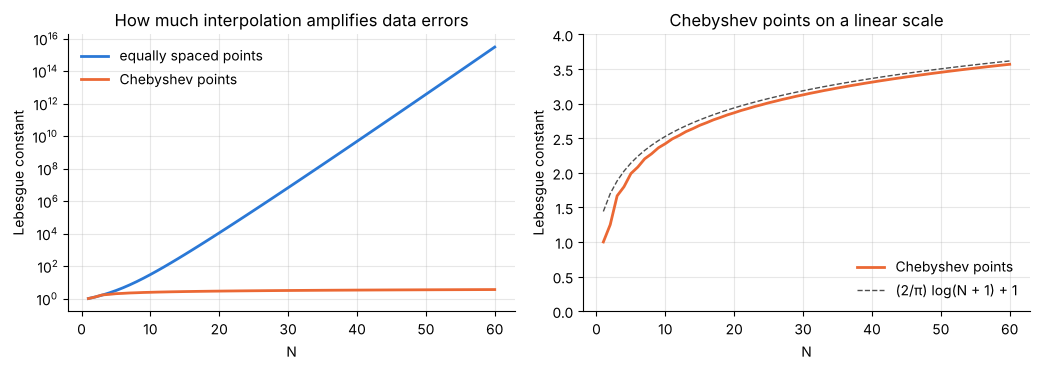

In [13]:
def lebesgue_constant(nodes, n_eval=20001):
    """Largest value of Σ|ℓ_j(x)| on [-1, 1], sampled at n_eval points."""
    x_eval = np.linspace(-1, 1, n_eval)
    diff = x_eval[:, None] - nodes[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    node_polynomial = np.abs(diff).prod(axis=1)                # |p(x)|
    lebesgue_function = node_polynomial * (np.abs(barycentric_weights(nodes)) / np.abs(diff)).sum(axis=1)
    lebesgue_function[exact.any(axis=1)] = 1.0                 # at a node the sum is exactly 1
    return lebesgue_function.max()

N_values = np.arange(1, 61)
lebesgue_equi = np.array([lebesgue_constant(equispaced_points(N)) for N in N_values])
lebesgue_cheb = np.array([lebesgue_constant(chebyshev_points(N)) for N in N_values])
bound = 2 / np.pi * np.log(N_values + 1) + 1

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].semilogy(N_values, lebesgue_equi, label="equally spaced points")
axes[0].semilogy(N_values, lebesgue_cheb, label="Chebyshev points")
axes[0].set(xlabel="N", ylabel="Lebesgue constant", title="How much interpolation amplifies data errors")
axes[0].legend(frameon=False, loc="upper left")
axes[1].plot(N_values, lebesgue_cheb, color="C1", label="Chebyshev points")
axes[1].plot(N_values, bound, "--", color="0.3", lw=1, label="(2/π) log(N + 1) + 1")
axes[1].set(xlabel="N", ylabel="Lebesgue constant", ylim=(0, 4), title="Chebyshev points on a linear scale")
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()

In [14]:
first_above = N_values[lebesgue_equi > 1e10][0]
print("  N    equally spaced    Chebyshev    (2/π) log(N+1) + 1")
for N in (10, 20, 30, 40, 50, 60):
    print(f"{N:3d} {lebesgue_equi[N - 1]:14.1e} {lebesgue_cheb[N - 1]:12.3f} {bound[N - 1]:14.3f}")
print(f"the equally spaced constant first exceeds 1e10 at N = {first_above}")
assert np.all(lebesgue_cheb < bound) and lebesgue_cheb[-1] < 4
assert first_above == 42 and N_values[lebesgue_equi > 1e12][0] == 49
assert abs(lebesgue_equi[N_values == 50][0] / (2.0**51 / (np.e * 50 * np.log(50))) - 1) < 0.25      # the known asymptotic growth law

  N    equally spaced    Chebyshev    (2/π) log(N+1) + 1
 10        3.0e+01        2.421          2.527
 20        1.1e+04        2.868          2.938
 30        6.6e+06        3.127          3.186
 40        4.7e+09        3.310          3.364
 50        3.6e+12        3.453          3.503
 60        3.0e+15        3.569          3.617
the equally spaced constant first exceeds 1e10 at N = 42


For Chebyshev points the constant grows only logarithmically and stays below the bound
$\tfrac2\pi\log(N+1) + 1$: it is 2.4 at $N = 10$ and still below 4 at $N = 60$. Interpolation
in Chebyshev points returns the data errors essentially unamplified, and is never more than a
small factor away from the best polynomial approximation.

For equally spaced points the constant grows like $2^{N+1}/(eN\log N)$. It passes $10^{10}$
at $N = 42$ and $10^{12}$ at $N = 49$. Rounding errors of $10^{-16}$ in the data are by then
amplified to $10^{-4}$, and measurement errors of $10^{-3}$ to nonsense. So even a function
that is analytic in the whole lens of 4.4, for which the exact interpolants converge, cannot be
interpolated in many equally spaced points on a computer.

## 4.7 How fast: the Bernstein ellipse

The equipotentials of the Chebyshev points are ellipses with foci at $\pm1$. Label each by the
sum $\rho$ of its two semi-axes, so that $\rho = 1$ is the interval itself and larger $\rho$
means a larger ellipse. On the ellipse with label $\rho$ the potential is $\log(\rho/2)$. Insert
this, and $\phi(x) = -\log 2$ on the interval, into the error estimate of 4.4:

$$|f(x) - P(x)| \approx \text{const} \times e^{N[-\log 2 - \log(\rho/2)]} = \text{const} \times \rho^{-N} .$$

So if $f$ is analytic inside the ellipse with foci $\pm1$ whose semi-axes sum to $\rho$, called
the **Bernstein ellipse**, the interpolation error in Chebyshev points is $O(\rho^{-N})$.
This is the counterpart of the strip of analyticity of notebook 3, with the same message: the
convergence rate is fixed by the distance of the nearest singularity in the complex plane.

**By hand.** An ellipse with foci $\pm1$ and semi-axes $a > b$ has $a^2 - b^2 = 1$. A pole on
the imaginary axis at $\pm ib$ lies at the end of the minor axis, so $a = \sqrt{1 + b^2}$ and
$\rho = b + \sqrt{1 + b^2}$. A singularity on the real axis at $x_s > 1$ lies at the end of the
major axis, so $\rho = x_s + \sqrt{x_s^2 - 1}$.

| Function | Singularities | $\rho$ |
| --- | --- | --- |
| $1/(1 + 25x^2)$ | poles at $\pm i/5$ | $(1 + \sqrt{26})/5 = 1.2198$ |
| $1/(1 + 4x^2)$ | poles at $\pm i/2$ | $(1 + \sqrt5)/2 = 1.6180$ |

1/(1 + 25x²): measured ρ = 1.2193   predicted ρ = 1.2198
1/(1 + 4x²): measured ρ = 1.6168   predicted ρ = 1.6180


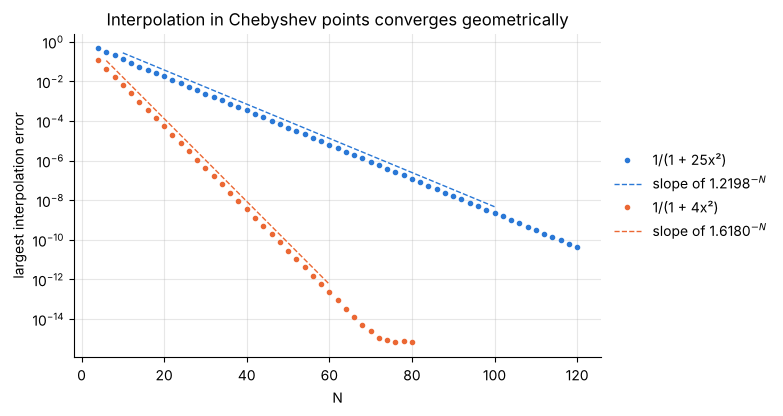

In [15]:
def chebyshev_error(f, N):
    x = chebyshev_points(N)
    return np.abs(barycentric_interpolate(f(x), x_fine) - f(x_fine)).max()

cases = {"1/(1 + 25x²)": (runge, (1 + np.sqrt(26)) / 5, np.arange(4, 121, 2), (10, 100)),
         "1/(1 + 4x²)": (lambda x: 1 / (1 + 4 * x**2), (1 + np.sqrt(5)) / 2, np.arange(4, 81, 2), (6, 60))}

fig, ax = plt.subplots(figsize=(6.8, 4.2))
for name, (f, rho, N_range, (low, high)) in cases.items():
    errors = np.array([chebyshev_error(f, N) for N in N_range])
    window = (N_range >= low) & (N_range <= high)              # before rounding errors take over
    rho_measured = np.exp(-np.polyfit(N_range[window], np.log(errors[window]), 1)[0])
    print(f"{name}: measured ρ = {rho_measured:.4f}   predicted ρ = {rho:.4f}")
    assert abs(rho_measured / rho - 1) < 0.02
    line, = ax.semilogy(N_range, errors, "o", ms=3, label=name)
    ax.semilogy(N_range[window], 2 * rho ** (-N_range[window].astype(float)), "--", lw=1, color=line.get_color(), label=f"slope of {rho:.4f}$^{{-N}}$")
ax.set(xlabel="N", ylabel="largest interpolation error", title="Interpolation in Chebyshev points converges geometrically")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))

# the potential of the Chebyshev points at the pole 0.2i equals log(ρ/2)
assert abs(potential(np.array([0.2j]), chebyshev_points(2000))[0] - np.log(runge_rho / 2)) < 1e-3

Both rates agree with the ellipse prediction to a fraction of a per cent. The peak of
half-width $1/5$ needs about 12 more points for each further digit, the wider peak of
half-width $1/2$ fewer than 5. The practical reading is the same as in notebook 3: the sharper
the feature, the closer the singularity, the more points are needed, and the count can be
estimated in advance.

## 4.8 Worked example: tabulating a property

**Problem.** The latent heat of vaporization of a liquid falls with temperature and vanishes at
the critical point. Watson's correlation scales a known value to other temperatures:

$$h_{fg}(T) = h_{fg,1}\left(\frac{T_c - T}{T_c - T_1}\right)^{0.38} .$$

For water $T_c = 647.1$ K, and $h_{fg,1} = 2257$ kJ/kg at $T_1 = 373.15$ K. A simulation code
needs $h_{fg}$ between 100 °C and 360 °C many millions of times, and will replace the
correlation by a polynomial through **12 tabulated values**. Where should the 12 temperatures
be placed?

**By hand.** Map the temperature range $[T_a, T_b]$ to $[-1, 1]$ by
$T = \tfrac12(T_a + T_b) + \tfrac12(T_b - T_a)\,x$.
The function has a branch point at $T_c$, where the curve becomes vertical. On the $x$ scale it
is at $x_s = (2T_c - T_a - T_b)/(T_b - T_a) = 1.107$, just beyond the hot end of the table.
The ellipse through it has $\rho = x_s + \sqrt{x_s^2 - 1} = 1.58$, so 12 Chebyshev points ($N = 11$)
should give an error of order $\rho^{-11} \approx 10^{-2}$ times a modest constant: a fraction
of a per cent or better.

branch point at x = 1.107,  ρ = 1.583
Chebyshev temperatures (°C): [100.  105.3 120.6 144.9 176.  211.5 248.5 284.  315.1 339.4 354.7 360. ]

points    worst error, equally spaced    worst error, Chebyshev    ratio
   8                6.990 kJ/kg              2.8727 kJ/kg          2
  12                1.474 kJ/kg              0.2655 kJ/kg          6
  16                0.378 kJ/kg              0.0296 kJ/kg         13
  24                0.033 kJ/kg              0.0004 kJ/kg         75


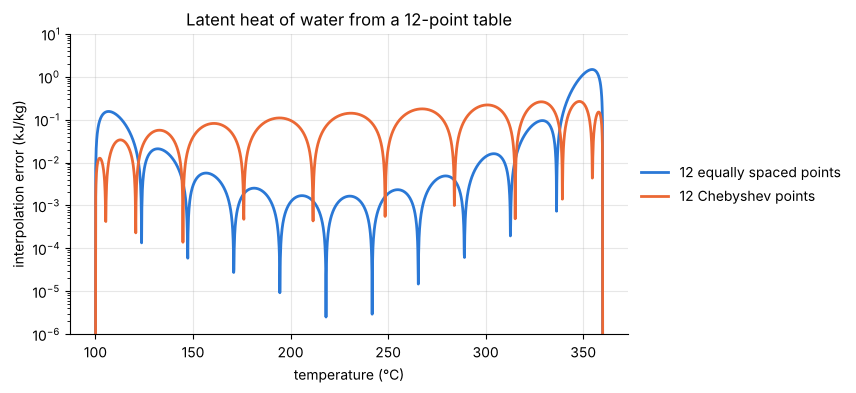

In [16]:
T_critical, T_ref, h_ref = 647.1, 373.15, 2257.0

def latent_heat(T):                                            # kJ/kg, T in K
    return h_ref * ((T_critical - T) / (T_critical - T_ref)) ** 0.38

T_a, T_b = 373.15, 633.15                                      # 100 °C to 360 °C
N = 11                                                         # 12 points
to_T = lambda x: (T_a + T_b) / 2 + (T_b - T_a) / 2 * x
T_fine = to_T(x_fine)

x_singular = (2 * T_critical - T_a - T_b) / (T_b - T_a)
print(f"branch point at x = {x_singular:.3f},  ρ = {x_singular + np.sqrt(x_singular**2 - 1):.3f}")

def table_errors(N):
    """Interpolation errors (kJ/kg) on the fine grid for N + 1 equally spaced and N + 1 Chebyshev temperatures."""
    from_equispaced = lagrange_interpolate(equispaced_points(N), latent_heat(to_T(equispaced_points(N))), x_fine)
    from_chebyshev = barycentric_interpolate(latent_heat(to_T(chebyshev_points(N))), x_fine)
    return np.abs(from_equispaced - latent_heat(T_fine)), np.abs(from_chebyshev - latent_heat(T_fine))

print("Chebyshev temperatures (°C):", np.round(to_T(chebyshev_points(N))[::-1] - 273.15, 1))
print("\npoints    worst error, equally spaced    worst error, Chebyshev    ratio")
for points in (8, 12, 16, 24):
    e_equi, e_cheb = table_errors(points - 1)
    print(f"{points:4d} {e_equi.max():20.3f} kJ/kg {e_cheb.max():19.4f} kJ/kg {e_equi.max() / e_cheb.max():10.0f}")

error_equispaced, error_chebyshev = table_errors(N)
assert error_chebyshev.max() < 0.3 and error_equispaced.max() > 5 * error_chebyshev.max()
assert table_errors(23)[0].max() > 50 * table_errors(23)[1].max()            # 24 points

fig, ax = plt.subplots(figsize=(7.2, 3.9))
ax.semilogy(T_fine - 273.15, np.maximum(error_equispaced, 1e-8), label="12 equally spaced points")
ax.semilogy(T_fine - 273.15, np.maximum(error_chebyshev, 1e-8), label="12 Chebyshev points")
ax.set(xlabel="temperature (°C)", ylabel="interpolation error (kJ/kg)", ylim=(1e-6, 10),
       title="Latent heat of water from a 12-point table")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

The same 12 function values, placed differently, give a worst error more than five times
smaller: 0.27 kJ/kg against 1.47 kJ/kg, on values between 730 and 2257 kJ/kg. The equally spaced table is
excellent in the middle of the range and poor at the hot end, where the curve steepens towards
the critical point. The Chebyshev table spreads its error far more evenly, and its advantage grows with
the number of points: a factor of 13 with 16 points and of 75 with 24. Nothing diverges
here, because the singularity lies on the real axis outside the lens of 4.4, but the
equally spaced table converges at a much lower rate.

The general advice for engineering practice:

- **If you can choose where to sample**, cluster the points towards the ends of the interval in
  the Chebyshev pattern. This applies to sensor positions along a rod or across a channel, the
  design points of a computer experiment, and the tabulation points of a property correlation.
- **If the data are already equally spaced**, do not pass one high-degree polynomial through
  all of them. Use low-degree pieces instead (a spline, or local finite difference formulas as
  in notebook 1), or fit a low-degree polynomial by least squares.

## Summary

- The barycentric formula evaluates the interpolating polynomial in $O(N)$ operations per point
  from the weights $\lambda_j = 1/\prod_{k\ne j}(x_j - x_k)$. It is stable where solving the
  Vandermonde system for monomial coefficients breaks down near $N = 40$.
- In equally spaced points the node polynomial is about $2^N$ times larger near the ends than in
  the middle. Interpolants of smooth functions can diverge (the Runge phenomenon), and data
  errors are amplified by a Lebesgue constant that grows like $2^N$.
- The Chebyshev points $x_j = \cos(j\pi/N)$ have density $N/(\pi\sqrt{1 - x^2})$. Their potential
  is constant on the interval, their Lebesgue constant grows like $\log N$, and their
  barycentric weights are $(-1)^j$ with the two end weights halved.
- For a function analytic inside the Bernstein ellipse with parameter $\rho$, interpolation in
  Chebyshev points converges like $\rho^{-N}$.
- Sample at clustered points when you can choose. Do not fit one high-degree polynomial to
  equally spaced data.

Notebook 5 differentiates the Chebyshev interpolant, using the weights $\lambda_j$ again, to
obtain a spectral method for bounded intervals. `barycentric_interpolate(values, x_eval)` is
used unchanged in later notebooks.

## Exercises

1. Compute the barycentric weights $\lambda_0, \dots, \lambda_3$ of the four Chebyshev points
   with $N = 3$ by hand from the definition in 4.1, and check them with `barycentric_weights`.
   Confirm that they are $2^{N-1}/N$ times the pattern $\tfrac12, -1, 1, -\tfrac12$. Then
   interpolate $f(x) = x^3 - x$ through those four points and verify that
   `barycentric_interpolate` returns $f(0.3)$ exactly.
2. The family $f(x) = \dfrac{1}{1 + (x/c)^2}$ has poles at $\pm ic$. According to 4.4,
   interpolation in equally spaced points converges on the whole interval only if the poles lie
   outside the lens that crosses the imaginary axis at $\pm0.5255i$. Test this for $c = 0.4$ and
   $c = 0.7$: tabulate the largest error on $[-1, 1]$ for $N = 10, 20, 30, 40$ with
   `lagrange_interpolate`. Which case converges? Then confirm the number 0.5255 by solving
   $\phi(iy) = -1 + \log 2$ with `scipy.optimize.brentq` and `equispaced_limit_potential`.
3. The function $f(x) = |x|$ is continuous but has a kink at $x = 0$. Compute the largest error
   of the Chebyshev interpolant on $[-1, 1]$ for $N = 10, 20, 40, 80, 160, 320$ and estimate the
   algebraic order of convergence. Compare with the geometric convergence of 4.7 and explain
   the difference in terms of the Bernstein ellipse.
4. The velocity across a thin shear layer is modelled by $u(x) = \tanh(10x)$ on $[-1, 1]$. It is
   to be reconstructed from 21 probes ($N = 20$). Compare the largest reconstruction error for
   probes at equally spaced and at Chebyshev positions. The nearest singularities of $u$ are at
   $x = \pm i\pi/20$: compute $\rho$, predict how many Chebyshev probes are needed for an error
   below $10^{-6}$, and check the prediction.
5. Lebesgue constants in action. Sample $f(x) = \cos 3x$ at $N + 1 = 31$ points, add noise of
   standard deviation $10^{-8}$ to the samples with `np.random.default_rng(0)`, and compute the
   largest error of the interpolant on $[-1, 1]$, for equally spaced and for Chebyshev points.
   Compare each error with $10^{-8}\,\Lambda_N$ from `lebesgue_constant`. Which point set
   returns the noise unamplified?